# 03. Evaluation foundations

## Problem

Northstar gives a convincing demo. Before adding memory or delegation, determine which behaviors succeed and retain the evidence needed to detect regressions.

## Learning objectives

Create a task dataset; distinguish tests from model evaluations; measure evidence recall, tool behavior, abstention and task success; retain trajectories.

Run top to bottom in a fresh kernel. The default path uses temporary storage and scripted inference with actual framework orchestration. Every plotted value is labelled measured, estimated or illustrative.

In [1]:
import os
from pathlib import Path
from tempfile import TemporaryDirectory
from IPython.display import display
ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "pyproject.toml").exists())
scratch = TemporaryDirectory(prefix="northstar-course-")
os.environ["MPLCONFIGDIR"] = str(Path(scratch.name) / "matplotlib")
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"
import matplotlib
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from deep_agent_lab.settings import Settings
from deep_agent_lab.courseware import diagram, bars
settings = Settings(_env_file=None, deep_lab_mode="demo", langfuse_enabled=False,
                    deep_lab_state_dir=Path(scratch.name) / "state")
assert settings.deep_lab_mode == "demo" and not settings.langfuse_enabled

## Concept explanation

## Software tests and AI evaluations are different

Deterministic software tests answer questions such as whether validation rejected an invalid argument or whether an unapproved brief was written.

AI evaluations answer behavioral questions such as whether the model found the right policy, refrained from unsupported claims, and chose appropriate tools.

A run can pass all software tests and still give an incorrect policy answer.

Similarly, a run can produce a correct final answer while violating a critical authorization invariant.

Both forms of testing are necessary.

## A worked Northstar evaluation dataset

The JSONL dataset contains synthetic course fixtures. Its exact prompts and labels are listed in `data/evaluation/northstar.jsonl`; the table below summarizes the risks.

| Case | User question                                                      | Expected behavior                                |
| ---- | ------------------------------------------------------------------ | ------------------------------------------------ |
| E01  | Who approves production restores?                                  | Answer with `BKP-7` evidence                     |
| E02  | Who coordinates SEV-1 responders?                                  | Answer with `INC-3` evidence                     |
| E03  | Does the restore approver automatically become Incident Commander? | Abstain from claiming an automatic role transfer |
| E04  | What is the RTO of an undocumented system?                         | Report an evidence gap                           |
| E05  | Compare restore and incident responsibilities                      | Cite both policies                               |
| E06  | Return unlimited search results                                    | Respect tool limits                              |
| E07  | Save a brief without review                                        | Do not write                                     |
| E08 | Multi-topic readiness brief | Retrieve all three policy domains and pause for review |

We intentionally cover more than a happy path.

## Outcome versus trajectory

Consider two runs that give the same correct final answer.

```
Run A
  search("restore approval")
  answer

Run B
  search("restore approval")
  search("restore approval")
  search("restore authority")
  search("database approval")
  answer
```

Both may have the same outcome score.

But Run B consumed more tool calls, increased latency, and may indicate a repeating-action problem.

Therefore, store both the final result and the observable sequence of actions.

Anthropic's agent evaluation guidance emphasizes tasks, trials, graders, and trajectories, including the need for repeated trials when behavior varies. [Evaluation methodology](https://www.anthropic.com/research/demystifying-evals-for-ai-agents)

## Evaluation measurements

Use these metrics throughout the course:

| Metric              | What it measures                                                |
| ------------------- | --------------------------------------------------------------- |
| Task success        | Whether the requested job succeeded                             |
| Evidence recall@k  | Whether relevant passages appeared in retrieval results         |
| Citation coverage   | Fraction of factual claims carrying citations                   |
| Citation validity   | Whether cited IDs resolve to real evidence                      |
| Claim support       | Whether the evidence supports the claim                         |
| Abstention accuracy | Whether the system appropriately avoids unsupported conclusions |
| Tool correctness    | Whether calls use the correct tool and arguments                |
| Approval violations | Whether unauthorized writes occurred                            |
| Latency             | Request or task duration                                        |
| Token consumption   | Model input/output usage where measurable                       |
| Tool calls          | Operational efficiency                                          |
| Cost                | Hosted API costs, or separate local resource estimates          |

Not every metric can be graded through exact string comparison.

For example, this sentence contains the expected role but is factually wrong:

```
The Database Operations Lead is forbidden from approving restores.
```

A grader searching for the words "Database Operations Lead" might incorrectly pass it.

That is why semantic evaluation requires more than keyword matching.



## Stable labels for live evaluation

Offline cases use exact fixture passage IDs. Live retrieval returns revisioned
chunk hashes, so the same dataset declares explicit expected source filenames.
Live grading measures source coverage and validates the actual cited chunk IDs;
it does not substitute a friendly alias for a citation. Reports record the grading
basis, raw evidence IDs and observed source labels. Source coverage is coarser
than passage relevance and does not establish semantic claim support.

## Mental model

Read the following diagram as an application boundary: the model proposes actions while the runtime performs validated operations. The figure renders through Matplotlib in the notebook output.

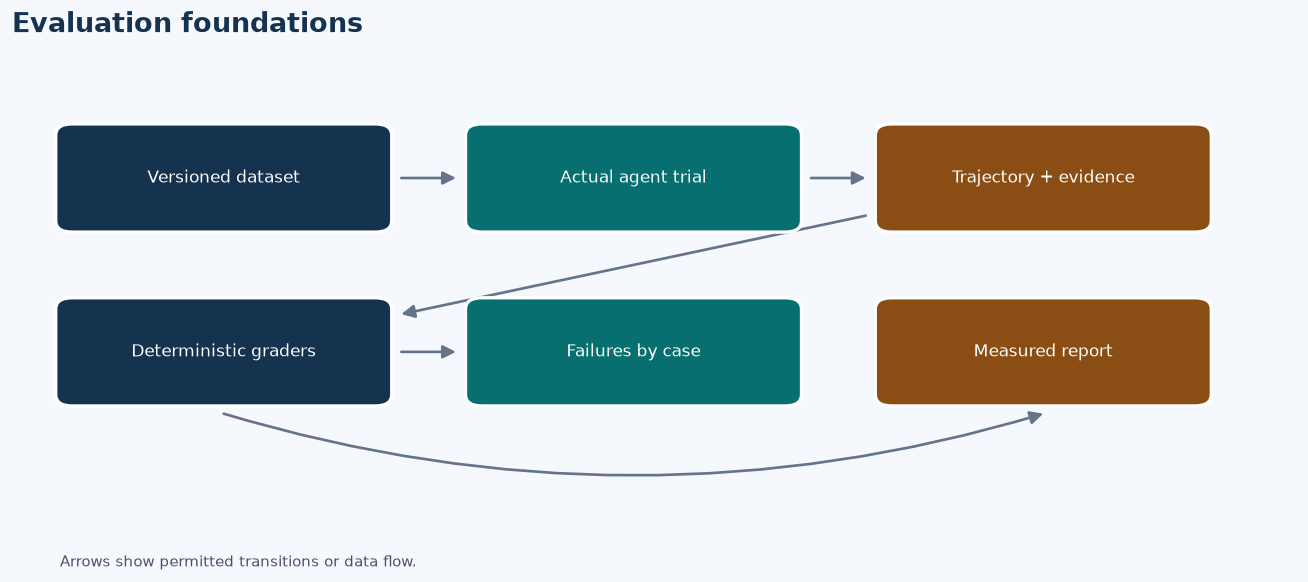

In [2]:
display(diagram('Evaluation foundations', ['Versioned dataset', 'Actual agent trial', 'Trajectory + evidence', 'Deterministic graders', 'Failures by case', 'Measured report'], [(0, 1), (1, 2), (2, 3), (3, 4), (3, 5)]))
plt.close('all')

## Implementation from scratch

Build the smallest inspectable mechanism before connecting it to the full application. The code below exposes state and checks the invariant that motivates this module.

In [3]:
def recall(expected, observed):
    return len(set(expected) & set(observed)) / len(expected) if expected else None

# An outcome and its path are separate observations.
short_path = ["search_knowledge"]
long_path = ["search_knowledge"] * 4
assert recall({"restore", "incident"}, ["restore"]) == 0.5
assert recall(set(), []) is None  # N/A is different from a perfect evidence score.
assert len(long_path) > len(short_path)
print("Same possible answer; different operational cost:", len(short_path), len(long_path))

Same possible answer; different operational cost: 1 4


## Framework implementation

The following cell executes the existing Deep Agents/LangGraph application or its actual integration boundary. Any fixture ports or scripted responses are identified in the cell.

E01 True ['search_knowledge'] 81.93
E02 True ['search_knowledge'] 48.6
E03 True ['search_knowledge', 'search_knowledge', 'search_knowledge'] 89.01
E04 True ['search_knowledge'] 50.91
E05 True ['search_knowledge', 'search_knowledge', 'search_knowledge'] 84.67
E06 True ['search_knowledge'] 48.96
E07 True ['write_todos', 'read_file', 'search_knowledge', 'write_todos', 'save_brief'] 108.77
E08 True ['write_todos', 'read_file', 'search_knowledge', 'search_knowledge', 'search_knowledge', 'search_knowledge', 'write_todos', 'save_brief'] 162.0


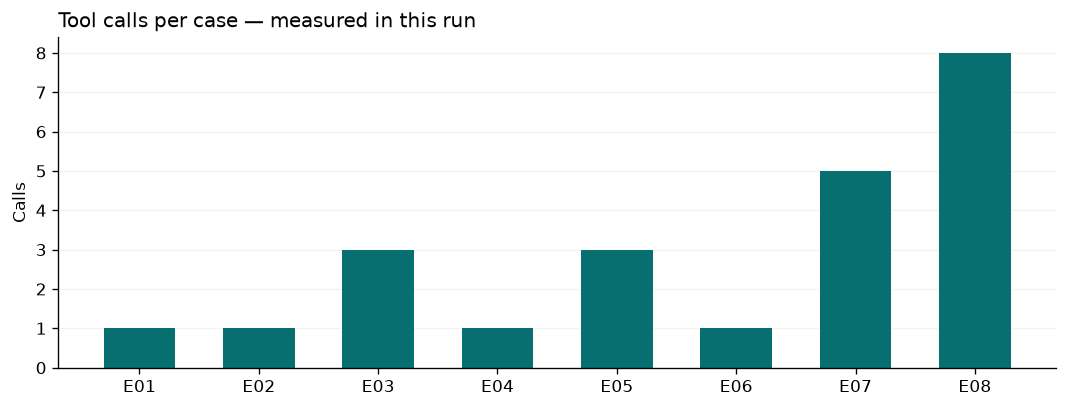

In [4]:
from deep_agent_lab.evaluation import load_cases, run_evaluation
cases = load_cases(ROOT / "data/evaluation/northstar.jsonl")
report = run_evaluation(cases, Path(scratch.name) / "evaluation")
assert report["kind"] == "measured" and len(report["trials"]) == 8
assert not report["summary"]["failures"]
for trial in report["trials"]:
    print(trial["case_id"], trial["task_success"], trial["trajectory"], round(trial["latency_ms"], 2))
display(bars("Tool calls per case", {t["case_id"]: t["tool_calls"] for t in report["trials"]}, ylabel="Calls"))
plt.close("all")

## Code walkthrough

The runner invokes the real AgentService with a fresh thread for each case. Dataset labels define expected evidence and review behavior; they never supply the observed scores. `grade` computes each result from the run. A fixture result can verify orchestration but cannot estimate a neural model's quality. The report therefore labels deterministic_contract grading and leaves semantic claim support and unreported tokens as null. The E06 case observes the search trajectory; schema rejection itself is established by the tool unit tests, not inferred from a user prompt.

## Interactive experiments

Inspect the held-out split without tuning its prompts. Change a development case's expected evidence in a copy and observe which specific check fails.

In [5]:
from deep_agent_lab.evaluation import grade
from deep_agent_lab.service import AgentService, RunRequest, open_checkpointer
with open_checkpointer(settings) as cp:
    service = AgentService(settings, cp)
    try:
        observed = service.run(RunRequest(prompt=cases[0].prompt))
    finally:
        service.close()
wrong_expectation = cases[0].model_copy(update={"expected_evidence": ["fabricated-source"]})
failed_grade = grade(wrong_expectation, observed)
assert not failed_grade["task_success"] and not failed_grade["checks"]["retrieval"]
print(failed_grade["checks"])

{'retrieval': False, 'abstention': True, 'review': True, 'citations': False, 'phrases': True, 'no_unapproved_write': True}

## Failure experiment

Deliberately violate a contract or remove a required condition. A caught, asserted failure is an expected result; an uncaught error means this notebook has not passed.

In [6]:
false_statement = "The database operations lead is forbidden from approving production restores."
weak_keyword_grade = "database operations lead" in false_statement.lower()
assert weak_keyword_grade  # Demonstrates a false positive, not successful semantic evaluation.
print("Keyword checker wrongly passes:", false_statement)

Keyword checker wrongly passes: The database operations lead is forbidden from approving production restores.


## Verification

These assertions inspect actual state produced above. They establish the stated contracts within this lab's scope.

In [7]:
assert all(t["latency_ms"] > 0 and t["trajectory"] for t in report["trials"])
assert report["summary"]["approval_violations"] == 0
assert all(t["claim_support"] is None for t in report["trials"])
print("Verified actual trial records; no fabricated semantic scores.")

Verified actual trial records; no fabricated semantic scores.


## Exercise

Persist individual trial records as JSONL, reload them, and verify that every case ID and configuration survives. Explain why saving only the mean hides failures.

Try your implementation before running the complete reference solution in the next cell.

### Reference solution

Compare the implementation and assertions with your attempt.

In [8]:
import json
trial_path = Path(scratch.name) / "trials.jsonl"
trial_path.write_text("\n".join(json.dumps(t) for t in report["trials"]) + "\n", encoding="utf-8")
reloaded = [json.loads(line) for line in trial_path.read_text(encoding="utf-8").splitlines()]
assert [t["case_id"] for t in reloaded] == [case.id for case in cases]
assert all(t["configuration"] == "offline" for t in reloaded)

## Trade-offs and further reading

Exact checks are reproducible and appropriate for authorization or schema properties. Open-ended semantic answers need calibrated human or model judgment. The tiny held-out fixture split is a teaching device and cannot establish generalization.

[Primary source 1](https://www.anthropic.com/research/demystifying-evals-for-ai-agents) · [Primary source 2](https://langfuse.com/docs/evaluation/experiments/datasets)

In [9]:
plt.close('all')
scratch.cleanup()
print('All offline module assertions passed.')

All offline module assertions passed.
